In [2]:
libraries = [
    "numpy",
    "pandas",
    "sklearn",
    "matplotlib",
    "plotly"
]

for library in libraries:
    try:
        module = __import__(library)
        print(f"✅ {library}: installed")
    except ImportError:
        print(f"❌ {library}: not installed")

✅ numpy: installed
✅ pandas: installed
✅ sklearn: installed
✅ matplotlib: installed
❌ plotly: not installed


In [3]:
%pip install plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 51.3 MB/s  0:00:00 eta 0:00:01

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import plotly
import plotly.express as px

print("Plotly version:", plotly.__version__)
print("Plotly is ready!")

Plotly version: 7.1.0
Plotly is ready!


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

print("All project libraries imported successfully!")

All project libraries imported successfully!


In [8]:
import pandas as pd
import numpy as np
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("\n✅ Machine-learning environment is ready!")


Pandas: 3.0.6
NumPy: 2.0.2
Scikit-learn: 1.9.0

✅ Machine-learning environment is ready!


In [9]:
%pip install earthaccess requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 10.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 23.2 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20/20 [earthaccess] [s3fs]tp]]r]

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:
import requests

url = "https://cmr.earthdata.nasa.gov/search/collections.json"

try:
    response = requests.get(url, timeout=20)
    response.raise_for_status()

    print("✅ NASA Earthdata catalogue is accessible!")
    print("HTTP status:", response.status_code)

except requests.RequestException as e:
    print("❌ Connection error:", e)

✅ NASA Earthdata catalogue is accessible!
HTTP status: 200


In [16]:
import requests

url = "https://cmr.earthdata.nasa.gov/search/collections.json"

params = {
    "keyword": "Landsat Collection 2 Level-2",
    "page_size": 10
}

try:
    response = requests.get(url, params=params, timeout=30)

    print("HTTP status:", response.status_code)
    response.raise_for_status()

    data = response.json()
    collections = data.get("feed", {}).get("entry", [])

    print("Collections found:", len(collections))

    for collection in collections:
        print("\nDataset:", collection.get("title"))
        print("Short name:", collection.get("short_name"))
        print("Collection ID:", collection.get("id"))

    if not collections:
        print("No collections returned. We will try a different search.")

except Exception as e:
    print("Error:", e)

HTTP status: 200
Collections found: 4

Dataset: Landsat Level-2 Surface Reflectance Collection 2
Short name: Landsat Level-2 Surface Reflectance Collection 2
Collection ID: C3442503899-USGS_EROS

Dataset: Landsat Level-2 Surface Temperature Collection 2
Short name: Landsat Level-2 Surface Temperature Collection 2
Collection ID: C3442506077-USGS_EROS

Dataset: Landsat Collection 2 - Level-2
Short name: landsat-2
Collection ID: C3108204618-INPE

Dataset: Landsat Collection 2 - Level-2 - Data Cube - LCF 16 days
Short name: LANDSAT-16D-1
Collection ID: C3108204500-INPE


In [17]:
import requests

url = "https://cmr.earthdata.nasa.gov/search/collections.json"

params = {
    "short_name": "LANDSAT_LC08_C02_T1_L2",
    "page_size": 5
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

collections = response.json().get("feed", {}).get("entry", [])

print("Collections found:", len(collections))

for collection in collections:
    print("\nTitle:", collection.get("title"))
    print("Short name:", collection.get("short_name"))
    print("Version:", collection.get("version_id"))
    print("Collection ID:", collection.get("id"))

Collections found: 0


In [18]:
import pandas as pd

df = pd.read_csv("UrbanHeatHotspots_Bengaluru.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (5000, 4)


,latitude,longitude,LST_C,NDVI
0,13.076240,77.492284,29.455819,0.253171
1,13.111811,77.656671,30.587183,0.090267
2,12.953024,77.497061,30.559839,0.088514
3,12.993302,77.563471,31.626262,0.063009
4,12.845202,77.632923,31.110140,0.188449


In [19]:
print("Dataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTemperature statistics:")
print(df["LST_C"].describe())

#cleaning data
df = df.dropna(
    subset=["latitude", "longitude", "LST_C", "NDVI"]
).copy()

df = df.drop_duplicates()

print("Clean dataset shape:", df.shape)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   latitude   5000 non-null   float64
 1   longitude  5000 non-null   float64
 2   LST_C      5000 non-null   float64
 3   NDVI       5000 non-null   float64
dtypes: float64(4)
memory usage: 156.4 KB
None

Missing values:
latitude     0
longitude    0
LST_C        0
NDVI         0
dtype: int64

Temperature statistics:
count    5000.000000
mean       31.338360
std         1.817874
min        23.477702
25%        30.337668
50%        31.421180
75%        32.480767
max        37.703501
Name: LST_C, dtype: float64
Clean dataset shape: (5000, 4)


In [22]:
print("Dataset shape:", df.shape)
print(df.head())
print("Missing coordinates:", df[["latitude", "longitude"]].isnull().sum())

Dataset shape: (5000, 4)
    latitude  longitude      LST_C      NDVI
0  13.076240  77.492284  29.455819  0.253171
1  13.111811  77.656671  30.587183  0.090267
2  12.953024  77.497061  30.559839  0.088514
3  12.993302  77.563471  31.626262  0.063009
4  12.845202  77.632923  31.110140  0.188449
Missing coordinates: latitude     0
longitude    0
dtype: int64


In [23]:
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "iframe"

fig = px.scatter(
    x=[1, 2, 3, 4],
    y=[10, 20, 15, 25],
    title="Plotly Test"
)

fig.show()

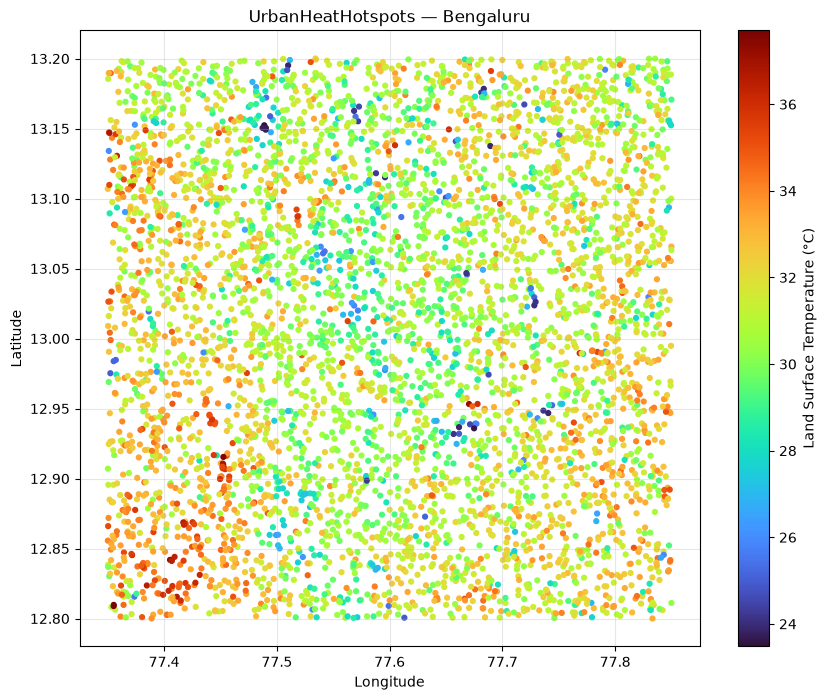

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["LST_C"],
    cmap="turbo",
    s=12
)

plt.colorbar(scatter, label="Land Surface Temperature (°C)")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("UrbanHeatHotspots — Bengaluru")
plt.grid(alpha=0.3)

plt.show()

In [29]:
#Machine learning...

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Input features
X = df[["latitude", "longitude", "NDVI"]]

# Target variable
y = df["LST_C"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Create model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train model
model.fit(X_train, y_train)

# Make predictions
predictions = model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("✅ Model trained successfully!")
print("Mean Absolute Error:", round(mae, 2), "°C")
print("R² Score:", round(r2, 3))

✅ Model trained successfully!
Mean Absolute Error: 0.96 °C
R² Score: 0.446


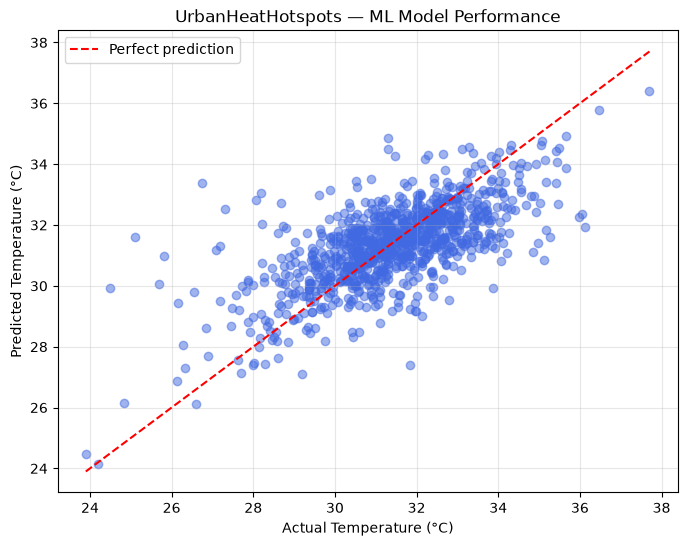

In [31]:
#
#Model Check1

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    predictions,
    alpha=0.5,
    color="royalblue"
)

minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.title("UrbanHeatHotspots — ML Model Performance")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [32]:
import numpy as np
import pandas as pd

# Define hotspots as the hottest 20% of observations
threshold = df["LST_C"].quantile(0.80)

df["Hotspot"] = np.where(
    df["LST_C"] >= threshold,
    "Hotspot",
    "Normal"
)

print("Hotspot threshold:", round(threshold, 2), "°C")

print("\nHotspot distribution:")
print(df["Hotspot"].value_counts())

Hotspot threshold: 32.74 °C

Hotspot distribution:
Hotspot
Normal     4000
Hotspot    1000
Name: count, dtype: int64


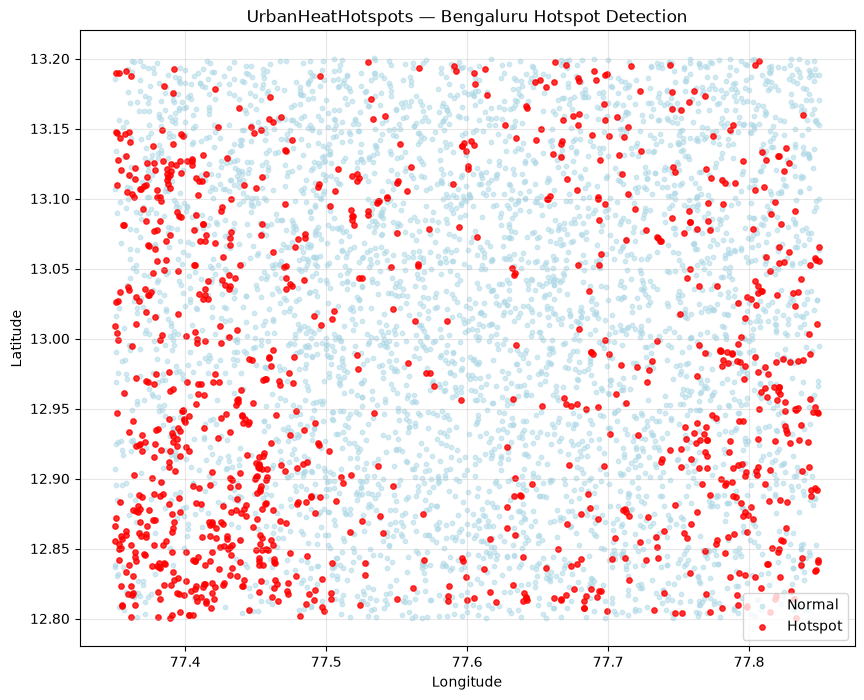

In [35]:
#Model check 2

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

normal = df[df["Hotspot"] == "Normal"]
hotspots = df[df["Hotspot"] == "Hotspot"]

plt.scatter(
    normal["longitude"],
    normal["latitude"],
    c="lightblue",
    s=10,
    alpha=0.5,
    label="Normal"
)

plt.scatter(
    hotspots["longitude"],
    hotspots["latitude"],
    c="red",
    s=15,
    alpha=0.8,
    label="Hotspot"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("UrbanHeatHotspots — Bengaluru Hotspot Detection")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [36]:
# Predict temperatures for all sampled locations
df["Predicted_LST"] = model.predict(
    df[["latitude", "longitude", "NDVI"]]
)

# Define predicted hotspots using the observed threshold
df["Predicted_Hotspot"] = np.where(
    df["Predicted_LST"] >= threshold,
    "Hotspot",
    "Normal"
)

print(df["Predicted_Hotspot"].value_counts())

Predicted_Hotspot
Normal     4237
Hotspot     763
Name: count, dtype: int64


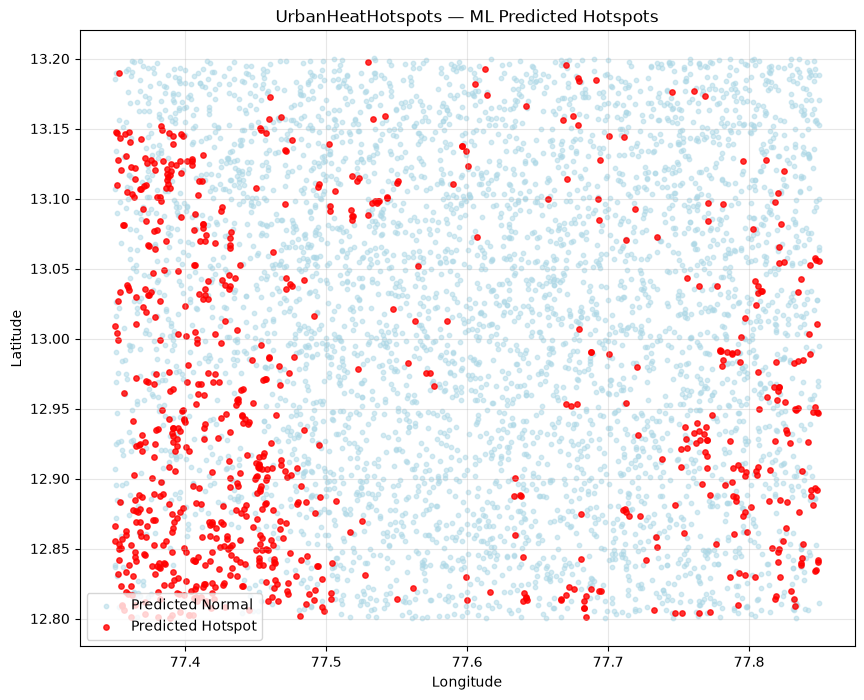

In [37]:
plt.figure(figsize=(10, 8))

predicted_normal = df[df["Predicted_Hotspot"] == "Normal"]
predicted_hotspots = df[df["Predicted_Hotspot"] == "Hotspot"]

plt.scatter(
    predicted_normal["longitude"],
    predicted_normal["latitude"],
    c="lightblue",
    s=10,
    alpha=0.5,
    label="Predicted Normal"
)

plt.scatter(
    predicted_hotspots["longitude"],
    predicted_hotspots["latitude"],
    c="red",
    s=15,
    alpha=0.8,
    label="Predicted Hotspot"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("UrbanHeatHotspots — ML Predicted Hotspots")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [43]:
import sys
import platform

print("Python:", sys.version)
print("Architecture:", platform.machine())

Python: 3.12.15 (main, Oct  1 2026, 00:00:00) [GCC 14.3.1 20251022 (Red Hat 14.3.1-4)]
Architecture: s390x


In [44]:
%pip install --upgrade pip setuptools wheel

  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 29.2 MB/s  0:00:00
Using cached setuptools-84.0.0-py3-none-any.whl (818 kB)
  Attempting uninstall: setuptools
    Found existing installation: setuptools 78.1.1
    Uninstalling setuptools-78.1.1:
      Successfully uninstalled setuptools-78.1.1 0/2 [setuptools]
  Attempting uninstall: pip━━━━━━━━━━━━━━━━━━━━━ 0/2 [setuptools]
    Found existing installation: pip 26.1.2━ 0/2 [setuptools]
    Uninstalling pip-26.1.2:━━━━━━━━━━━━━━━━ 0/2 [setuptools]
      Successfully uninstalled pip-26.1.2m━━━━━━━━━━━━━━━━━━━ 1/2 [pip]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pip]1/2 [pip]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.11.0+cpu requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.
Note: you may need

In [7]:
import pandas as pd

# Load the satellite dataset
df = pd.read_csv("UrbanHeatHotspots_Bengaluru.csv")

print("Dataset loaded:", df.shape)

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

X = df[["latitude", "longitude", "NDVI"]]
y = df["LST_C"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model trained!")
print("MAE:", mean_absolute_error(y_test, predictions))
print("R²:", r2_score(y_test, predictions))

# Save model
joblib.dump(model, "urban_heat_model.pkl")

print("Model saved successfully!")

Dataset loaded: (5000, 4)
Model trained!
MAE: 0.9585054021618002
R²: 0.4456272097866486
Model saved successfully!


In [8]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, clear_output

# Prepare predictions
df["Predicted_LST"] = model.predict(
    df[["latitude", "longitude", "NDVI"]]
)

# Hotspot threshold
threshold = df["LST_C"].quantile(0.80)

# Dropdown selector
map_selector = widgets.Dropdown(
    options=[
        "Observed Temperature",
        "Observed Hotspots",
        "Predicted Temperature",
        "Predicted Hotspots"
    ],
    value="Observed Temperature",
    description="Map:"
)

# Output area
output = widgets.Output()

def update_map(change=None):
    with output:
        clear_output(wait=True)

        selection = map_selector.value

        fig, ax = plt.subplots(figsize=(10, 7))

        if selection == "Observed Temperature":
            scatter = ax.scatter(
                df["longitude"],
                df["latitude"],
                c=df["LST_C"],
                cmap="turbo",
                s=12
            )
            fig.colorbar(scatter, ax=ax, label="Temperature (°C)")

        elif selection == "Predicted Temperature":
            scatter = ax.scatter(
                df["longitude"],
                df["latitude"],
                c=df["Predicted_LST"],
                cmap="turbo",
                s=12
            )
            fig.colorbar(scatter, ax=ax, label="Predicted Temperature (°C)")

        elif selection == "Observed Hotspots":
            colors = np.where(
                df["LST_C"] >= threshold,
                "red",
                "lightblue"
            )

            ax.scatter(
                df["longitude"],
                df["latitude"],
                c=colors,
                s=12
            )

        else:
            colors = np.where(
                df["Predicted_LST"] >= threshold,
                "red",
                "lightblue"
            )

            ax.scatter(
                df["longitude"],
                df["latitude"],
                c=colors,
                s=12
            )

        ax.set_title(selection)
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.grid(alpha=0.3)

        plt.show()
        plt.close(fig)

map_selector.observe(update_map, names="value")

display(widgets.VBox([
    widgets.HTML("<h2>🌡️ UrbanHeatHotspots — Bengaluru</h2>"),
    widgets.HTML(
        f"<b>Hotspot threshold:</b> {threshold:.2f}°C | "
        f"<b>Model MAE:</b> 0.96°C | "
        f"<b>R²:</b> 0.446"
    ),
    map_selector,
    output
]))

update_map()

In [9]:
import pandas as pd
import numpy as np
from IPython.display import display, HTML

# Calculate statistics
avg_temp = df["LST_C"].mean()
max_temp = df["LST_C"].max()
min_temp = df["LST_C"].min()

threshold = df["LST_C"].quantile(0.80)

hotspot_count = (df["LST_C"] >= threshold).sum()
hotspot_percentage = hotspot_count / len(df) * 100

avg_ndvi = df["NDVI"].mean()

# Create dashboard summary
summary_html = f"""
<div style="
    background-color:#17202A;
    padding:25px;
    border-radius:15px;
    color:white;
">
    <h2>🌡️ Urban Heat Analysis Summary</h2>

    <h3>Average Temperature: {avg_temp:.2f} °C</h3>
    <h3>Maximum Temperature: {max_temp:.2f} °C</h3>
    <h3>Minimum Temperature: {min_temp:.2f} °C</h3>

    <hr>

    <h3>🔴 Observed Hotspot Points: {hotspot_count}</h3>
    <h3>🔥 Hotspot Percentage: {hotspot_percentage:.1f}%</h3>

    <hr>

    <h3>🌿 Average NDVI: {avg_ndvi:.3f}</h3>
</div>
"""

display(HTML(summary_html))

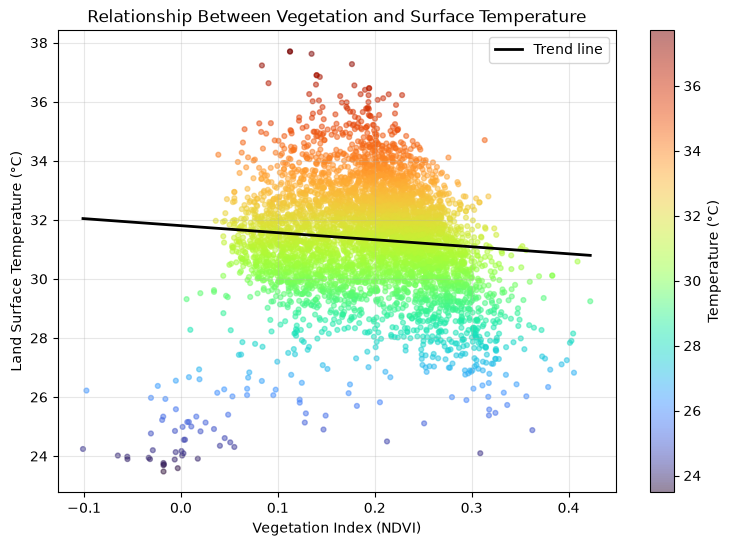

NDVI–Temperature Correlation: -0.088


In [10]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 6))

plt.scatter(
    df["NDVI"],
    df["LST_C"],
    c=df["LST_C"],
    cmap="turbo",
    alpha=0.5,
    s=12
)

# Trend line
x = df["NDVI"].to_numpy()
y = df["LST_C"].to_numpy()

slope, intercept = np.polyfit(x, y, 1)

plt.plot(
    np.sort(x),
    slope * np.sort(x) + intercept,
    color="black",
    linewidth=2,
    label="Trend line"
)

plt.xlabel("Vegetation Index (NDVI)")
plt.ylabel("Land Surface Temperature (°C)")
plt.title("Relationship Between Vegetation and Surface Temperature")

plt.colorbar(label="Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

correlation = df["NDVI"].corr(df["LST_C"])

print("NDVI–Temperature Correlation:", round(correlation, 3))

In [11]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Prepare clean dataset
spatial_df = df[
    ["latitude", "longitude", "NDVI", "LST_C"]
].dropna().copy()

# Divide Bengaluru samples into geographic longitude bands
spatial_df["region"] = pd.qcut(
    spatial_df["longitude"],
    q=5,
    labels=False,
    duplicates="drop"
)

# Hold out the easternmost band
test_region = spatial_df["region"].max()

train_df = spatial_df[
    spatial_df["region"] != test_region
]

test_df = spatial_df[
    spatial_df["region"] == test_region
]

features = ["latitude", "longitude", "NDVI"]

X_train_spatial = train_df[features]
y_train_spatial = train_df["LST_C"]

X_test_spatial = test_df[features]
y_test_spatial = test_df["LST_C"]

# Train a separate model for spatial evaluation
spatial_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

spatial_model.fit(X_train_spatial, y_train_spatial)

# Evaluate on unseen geographic region
spatial_predictions = spatial_model.predict(X_test_spatial)

spatial_mae = mean_absolute_error(
    y_test_spatial,
    spatial_predictions
)

spatial_r2 = r2_score(
    y_test_spatial,
    spatial_predictions
)

print("SPATIAL VALIDATION RESULTS")
print("--------------------------")
print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print("Spatial MAE:", round(spatial_mae, 3), "°C")
print("Spatial R²:", round(spatial_r2, 3))

SPATIAL VALIDATION RESULTS
--------------------------
Training samples: 4000
Testing samples: 1000
Spatial MAE: 1.055 °C
Spatial R²: 0.117


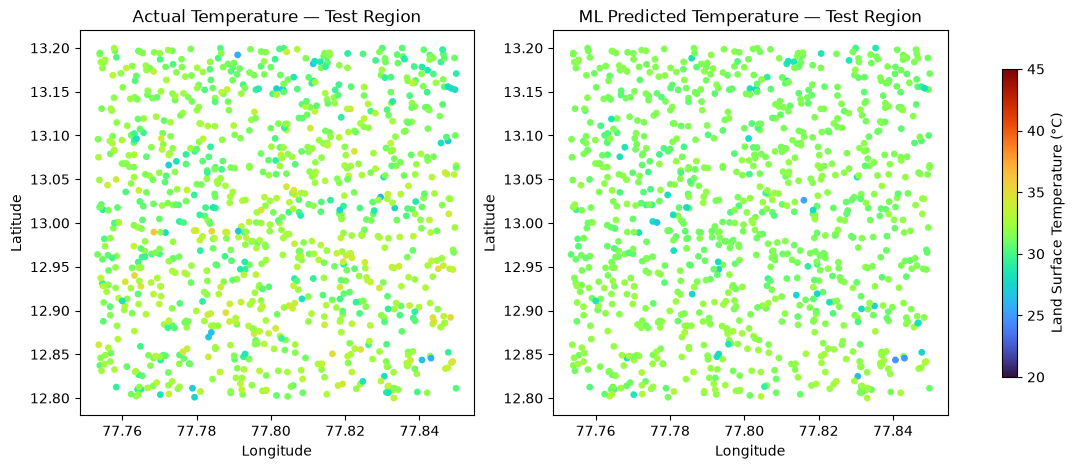

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual temperatures
actual = axes[0].scatter(
    test_df["longitude"],
    test_df["latitude"],
    c=y_test_spatial,
    cmap="turbo",
    vmin=20,
    vmax=45,
    s=15
)

axes[0].set_title("Actual Temperature — Test Region")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

# Predicted temperatures
predicted = axes[1].scatter(
    test_df["longitude"],
    test_df["latitude"],
    c=spatial_predictions,
    cmap="turbo",
    vmin=20,
    vmax=45,
    s=15
)

axes[1].set_title("ML Predicted Temperature — Test Region")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

fig.colorbar(
    actual,
    ax=axes,
    label="Land Surface Temperature (°C)",
    shrink=0.8
)

plt.show()

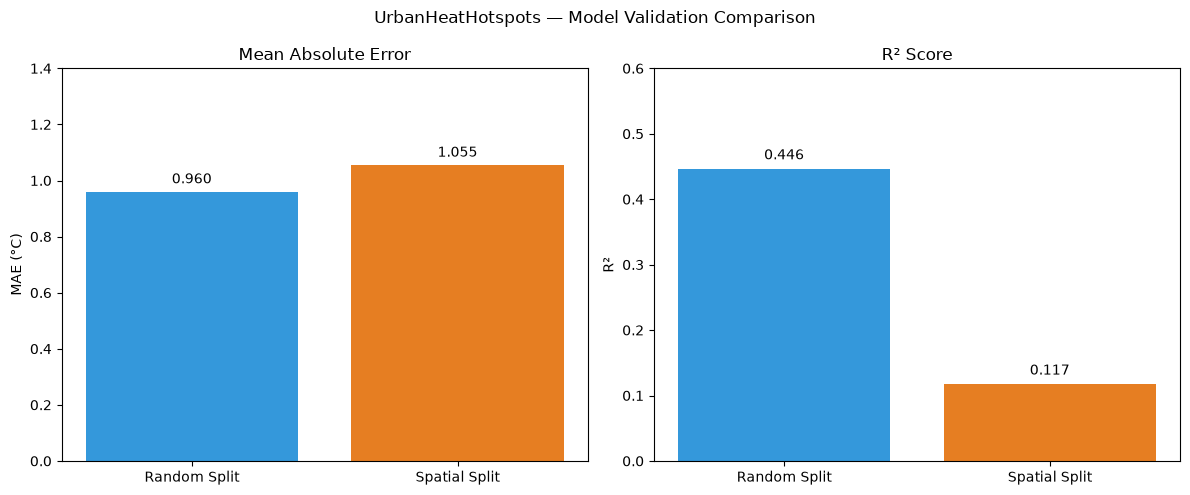

In [13]:
import matplotlib.pyplot as plt

metrics = ["MAE (°C)", "R²"]

random_scores = [0.960, 0.446]
spatial_scores = [1.055, 0.117]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# MAE comparison
axes[0].bar(
    ["Random Split", "Spatial Split"],
    [random_scores[0], spatial_scores[0]],
    color=["#3498db", "#e67e22"]
)

axes[0].set_title("Mean Absolute Error")
axes[0].set_ylabel("MAE (°C)")
axes[0].set_ylim(0, 1.4)

for i, value in enumerate([random_scores[0], spatial_scores[0]]):
    axes[0].text(i, value + 0.03, f"{value:.3f}", ha="center")

# R² comparison
axes[1].bar(
    ["Random Split", "Spatial Split"],
    [random_scores[1], spatial_scores[1]],
    color=["#3498db", "#e67e22"]
)

axes[1].set_title("R² Score")
axes[1].set_ylabel("R²")
axes[1].set_ylim(0, 0.6)

for i, value in enumerate([random_scores[1], spatial_scores[1]]):
    axes[1].text(i, value + 0.015, f"{value:.3f}", ha="center")

plt.suptitle("UrbanHeatHotspots — Model Validation Comparison")
plt.tight_layout()
plt.show()

In [14]:
import pandas as pd

df_new = pd.read_csv("UrbanHeatHotspots_Improved.csv")

print("Dataset shape:", df_new.shape)
print("\nColumns:", df_new.columns.tolist())

display(df_new.head())

Dataset shape: (5000, 5)

Columns: ['latitude', 'longitude', 'LST_C', 'NDVI', 'NDBI']


,latitude,longitude,LST_C,NDVI,NDBI
0,13.076240,77.492284,29.455819,0.650653,-0.220324
1,13.111811,77.656671,30.587183,0.194137,0.070278
2,12.953024,77.497061,30.559839,0.203565,-0.016069
3,12.993302,77.563471,31.626262,0.154746,0.036497
4,12.845202,77.632923,31.110140,0.423360,-0.059519


In [15]:
#Cleaning Dataset
df_new = df_new[
    ["latitude", "longitude", "LST_C", "NDVI", "NDBI"]
].copy()

df_new = df_new.replace([float("inf"), float("-inf")], float("nan"))

df_new = df_new.dropna().drop_duplicates()

print("Cleaned dataset:", df_new.shape)

print("\nTemperature statistics:")
print(df_new["LST_C"].describe())

print("\nNDVI and NDBI correlation with temperature:")
print(df_new[["NDVI", "NDBI", "LST_C"]].corr()["LST_C"])

Cleaned dataset: (5000, 5)

Temperature statistics:
count    5000.000000
mean       31.338360
std         1.817874
min        23.477702
25%        30.337668
50%        31.421180
75%        32.480767
max        37.703501
Name: LST_C, dtype: float64

NDVI and NDBI correlation with temperature:
NDVI    -0.178388
NDBI     0.683871
LST_C    1.000000
Name: LST_C, dtype: float64


In [18]:
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Divide the dataset into geographic regions
df_new["region"] = pd.qcut(
    df_new["longitude"],
    q=5,
    labels=False,
    duplicates="drop"
)

# Hold out easternmost region
test_region = df_new["region"].max()

train = df_new[df_new["region"] != test_region]
test = df_new[df_new["region"] == test_region]

# Target variable
y_train = train["LST_C"]
y_test = test["LST_C"]

# Model A: Without NDBI
features_a = ["latitude", "longitude", "NDVI"]

model_a = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model_a.fit(train[features_a], y_train)

pred_a = model_a.predict(test[features_a])

# Model B: With NDBI
features_b = ["latitude", "longitude", "NDVI", "NDBI"]

model_b = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model_b.fit(train[features_b], y_train)

pred_b = model_b.predict(test[features_b])

# Evaluation
mae_a = mean_absolute_error(y_test, pred_a)
r2_a = r2_score(y_test, pred_a)

mae_b = mean_absolute_error(y_test, pred_b)
r2_b = r2_score(y_test, pred_b)

print("MODEL COMPARISON")
print("------------------------------")

print("Model A — Without NDBI")
print("MAE:", round(mae_a, 3))
print("R²:", round(r2_a, 3))

print("\nModel B — With NDBI")
print("MAE:", round(mae_b, 3))
print("R²:", round(r2_b, 3))

MODEL COMPARISON
------------------------------
Model A — Without NDBI
MAE: 1.168
R²: -0.001

Model B — With NDBI
MAE: 0.83
R²: 0.446


In [21]:
import joblib
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

# Features for improved model
features = ["latitude", "longitude", "NDVI", "NDBI"]

# Train final model using all available data
final_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

final_model.fit(
    df_new[features],
    df_new["LST_C"]
)

# Generate fitted temperature estimates
df_new["Predicted_LST"] = final_model.predict(
    df_new[features]
)

# Define hotspot threshold
threshold_new = df_new["LST_C"].quantile(0.80)

df_new["Predicted_Hotspot"] = (
    df_new["Predicted_LST"] >= threshold_new
)

# Save improved model and dataset
joblib.dump(final_model, "urban_heat_model_improved.pkl")

df_new.to_csv(
    "urban_heat_data_improved.csv",
    index=False
)

print("Improved model saved successfully!")
print("Improved dataset saved successfully!")

print("\nHotspot threshold:", round(threshold_new, 2), "°C")
print(
    "Predicted hotspot points:",
    df_new["Predicted_Hotspot"].sum()
)

Improved model saved successfully!
Improved dataset saved successfully!

Hotspot threshold: 32.74 °C
Predicted hotspot points: 868


In [22]:
import pandas as pd
import joblib
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output, HTML

# Load improved dataset and model
dashboard_df = pd.read_csv("urban_heat_data_improved.csv")
dashboard_model = joblib.load("urban_heat_model_improved.pkl")

print("Dataset loaded:", dashboard_df.shape)
print("Model loaded:", type(dashboard_model).__name__)
print("Columns:", dashboard_df.columns.tolist())

Dataset loaded: (5000, 8)
Model loaded: RandomForestRegressor
Columns: ['latitude', 'longitude', 'LST_C', 'NDVI', 'NDBI', 'region', 'Predicted_LST', 'Predicted_Hotspot']


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets

from IPython.display import display, clear_output, HTML

# -------------------------------
# CONFIGURATION
# -------------------------------

df_dash = dashboard_df.copy()

features = ["latitude", "longitude", "NDVI", "NDBI"]

threshold = df_dash["LST_C"].quantile(0.80)

if "Predicted_LST" not in df_dash.columns:
    df_dash["Predicted_LST"] = dashboard_model.predict(
        df_dash[features]
    )

df_dash["Observed_Hotspot"] = df_dash["LST_C"] >= threshold

df_dash["Predicted_Hotspot"] = (
    df_dash["Predicted_LST"] >= threshold
)

avg_temp = df_dash["LST_C"].mean()
max_temp = df_dash["LST_C"].max()
avg_ndvi = df_dash["NDVI"].mean()

observed_count = int(df_dash["Observed_Hotspot"].sum())
predicted_count = int(df_dash["Predicted_Hotspot"].sum())

# -------------------------------
# DASHBOARD HEADER
# -------------------------------

display(HTML(f"""
<div style="
    background: linear-gradient(120deg, #12343b, #227c70);
    padding: 25px;
    border-radius: 15px;
    color: white;
">
    <h1>🌡️ UrbanHeatHotspots</h1>
    <h3>Bengaluru Urban Heat Analysis</h3>
    <p>
        Satellite-based land surface temperature analysis
        using Landsat imagery and Random Forest machine learning.
    </p>
</div>
"""))

# -------------------------------
# KEY STATISTICS
# -------------------------------

display(HTML(f"""
<div style="
    display: flex;
    flex-wrap: wrap;
    gap: 12px;
    margin: 18px 0;
">
    <div style="padding:15px;background:#e8f4f8;border-radius:10px;">
        <b>Average Surface Temperature</b><br>
        <span style="font-size:24px;color:#12343b;">
            {avg_temp:.2f} °C
        </span>
    </div>

    <div style="padding:15px;background:#fff0df;border-radius:10px;">
        <b>Hotspot Threshold</b><br>
        <span style="font-size:24px;color:#8a3d00;">
            {threshold:.2f} °C
        </span>
    </div>

    <div style="padding:15px;background:#fde8e8;border-radius:10px;">
        <b>Observed Hotspot Points</b><br>
        <span style="font-size:24px;color:#a40000;">
            {observed_count}
        </span>
    </div>

    <div style="padding:15px;background:#e8f5e9;border-radius:10px;">
        <b>Predicted Hotspot Points</b><br>
        <span style="font-size:24px;color:#1b5e20;">
            {predicted_count}
        </span>
    </div>
</div>
"""))

# -------------------------------
# MAP SELECTOR
# -------------------------------

map_selector = widgets.Dropdown(
    options=[
        "Observed Temperature",
        "Observed Hotspots",
        "Predicted Temperature",
        "Predicted Hotspots",
        "Vegetation Index (NDVI)",
        "Built-up Index (NDBI)"
    ],
    value="Observed Temperature",
    description="Visualization:",
    layout=widgets.Layout(width="450px")
)

map_output = widgets.Output()

def draw_map(change=None):

    with map_output:
        clear_output(wait=True)

        selection = map_selector.value

        fig, ax = plt.subplots(figsize=(10, 7))

        if selection == "Observed Temperature":
            values = df_dash["LST_C"]
            scatter = ax.scatter(
                df_dash["longitude"],
                df_dash["latitude"],
                c=values,
                cmap="turbo",
                s=15
            )
            fig.colorbar(
                scatter,
                ax=ax,
                label="Land Surface Temperature (°C)"
            )

        elif selection == "Predicted Temperature":
            values = df_dash["Predicted_LST"]
            scatter = ax.scatter(
                df_dash["longitude"],
                df_dash["latitude"],
                c=values,
                cmap="turbo",
                s=15
            )
            fig.colorbar(
                scatter,
                ax=ax,
                label="Estimated Temperature (°C)"
            )

        elif selection == "Observed Hotspots":
            colors = np.where(
                df_dash["Observed_Hotspot"],
                "red",
                "lightblue"
            )

            ax.scatter(
                df_dash["longitude"],
                df_dash["latitude"],
                c=colors,
                s=15
            )

        elif selection == "Predicted Hotspots":
            colors = np.where(
                df_dash["Predicted_Hotspot"],
                "red",
                "lightblue"
            )

            ax.scatter(
                df_dash["longitude"],
                df_dash["latitude"],
                c=colors,
                s=15
            )

        elif selection == "Vegetation Index (NDVI)":
            scatter = ax.scatter(
                df_dash["longitude"],
                df_dash["latitude"],
                c=df_dash["NDVI"],
                cmap="YlGn",
                s=15
            )
            fig.colorbar(
                scatter,
                ax=ax,
                label="NDVI"
            )

        else:
            scatter = ax.scatter(
                df_dash["longitude"],
                df_dash["latitude"],
                c=df_dash["NDBI"],
                cmap="RdYlBu_r",
                s=15
            )
            fig.colorbar(
                scatter,
                ax=ax,
                label="NDBI"
            )

        ax.set_title(selection, fontsize=15)
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.grid(alpha=0.25)

        plt.tight_layout()
        plt.show()
        plt.close(fig)

map_selector.observe(draw_map, names="value")

display(HTML("<h2>🗺️ Explore Satellite Maps</h2>"))
display(map_selector, map_output)

draw_map()

# -------------------------------
# MODEL PERFORMANCE
# -------------------------------

display(HTML("""
<h2>🤖 Machine Learning Evaluation</h2>
<p>Performance measured on a geographically held-out region.</p>
"""))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(
    ["Without NDBI", "With NDBI"],
    [1.168, 0.830]
)

axes[0].set_title("Spatial Mean Absolute Error")
axes[0].set_ylabel("MAE (°C)")

axes[1].bar(
    ["Without NDBI", "With NDBI"],
    [-0.001, 0.446]
)

axes[1].set_title("Spatial R² Score")
axes[1].set_ylabel("R²")
axes[1].axhline(0, linewidth=1)

plt.tight_layout()
plt.show()

# -------------------------------
# INTERACTIVE LOCATION EXPLORER
# -------------------------------

location_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(df_dash) - 1,
    step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="450px")
)

location_output = widgets.Output()

def show_location(change=None):

    with location_output:
        clear_output(wait=True)

        row = df_dash.iloc[location_slider.value]

        display(HTML(f"""
        <div style="
            padding:18px;
            border:1px solid #aaa;
            border-radius:10px;
        ">
            <h3>📍 Sampled Location Details</h3>
            <p><b>Latitude:</b> {row['latitude']:.5f}</p>
            <p><b>Longitude:</b> {row['longitude']:.5f}</p>
            <p><b>Observed Temperature:</b> {row['LST_C']:.2f} °C</p>
            <p><b>Estimated Temperature:</b> {row['Predicted_LST']:.2f} °C</p>
            <p><b>NDVI:</b> {row['NDVI']:.3f}</p>
            <p><b>NDBI:</b> {row['NDBI']:.3f}</p>
            <p><b>Observed Classification:</b>
            {'Hotspot' if row['LST_C'] >= threshold else 'Normal'}</p>
        </div>
        """))

location_slider.observe(show_location, names="value")

display(HTML("<h2>🔎 Inspect an Individual Sample</h2>"))
display(location_slider, location_output)

show_location()

# -------------------------------
# SCIENTIFIC LIMITATIONS
# -------------------------------

display(HTML("""
<div style="
    margin-top:20px;
    padding:18px;
    background:#fff3cd;
    border-radius:10px;
">
    <h3>⚠️ Interpretation and Limitations</h3>
    <ul>
        <li>Temperature values represent satellite-derived land surface
        temperature, not measured air temperature.</li>
        <li>Hotspots are defined relative to the 80th percentile of the
        sampled temperature distribution, not an official heat-danger threshold.</li>
        <li>The model has been evaluated on one geographically held-out region;
        further validation is required.</li>
        <li>Predicted values shown for training samples are fitted estimates,
        not independent test predictions.</li>
        <li>Results reflect the selected satellite imagery and are not a
        live heat forecast.</li>
    </ul>
</div>
"""))

NameError: name 'dashboard_df' is not defined